Mounted at /content/drive
Train/Val/Test: 2569 551 550
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved opt


ResNet50 Stage Dimensions
         Stage Output (H, W, C)
Stem + MaxPool     (56, 56, 64)
       conv2_x    (56, 56, 256)
       conv3_x    (28, 28, 512)
       conv4_x   (14, 14, 1024)
       conv5_x     (7, 7, 2048)

Attention Module Input and Output Dimensions
            Model     Module          Input         Output  Params
       A1_Channel      P3_ca (14, 14, 1024) (14, 14, 1024)  132160
       A2_Spatial      P3_sa (14, 14, 1024) (14, 14, 1024)      99
A3_ChannelSpatial      P3_ca (14, 14, 1024) (14, 14, 1024)  132160
A3_ChannelSpatial      P3_sa (14, 14, 1024) (14, 14, 1024)      99
 A4_SelfAttention    P3_self (14, 14, 1024) (14, 14, 1024) 1312001
      A5_Combined      P3_ca (14, 14, 1024) (14, 14, 1024)  132160
      A5_Combined      P3_sa (14, 14, 1024) (14, 14, 1024)      99
      A5_Combined    P3_self (14, 14, 1024) (14, 14, 1024) 1312001
            B1_P1      P1_ca  (56, 56, 256)  (56, 56, 256)    8464
            B1_P1      P1_sa  (56, 56, 256)  (56, 56, 256)      9

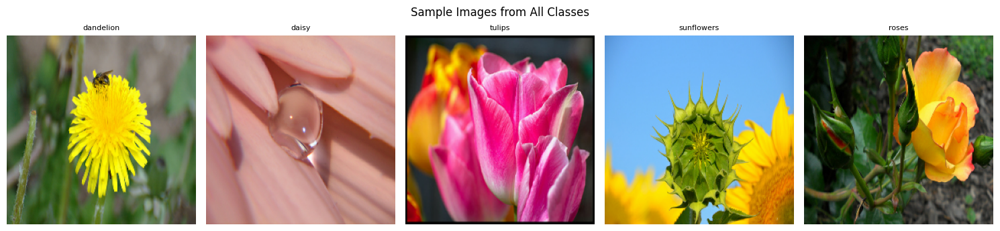

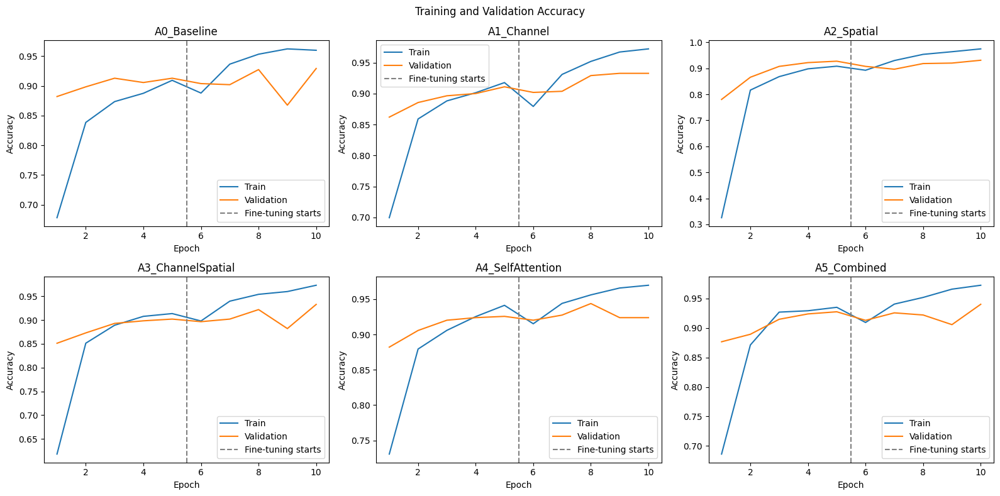

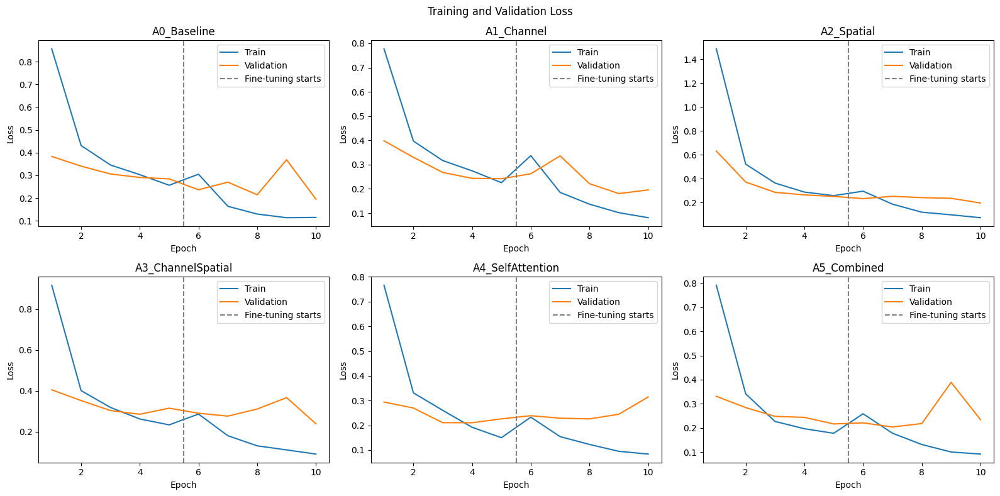

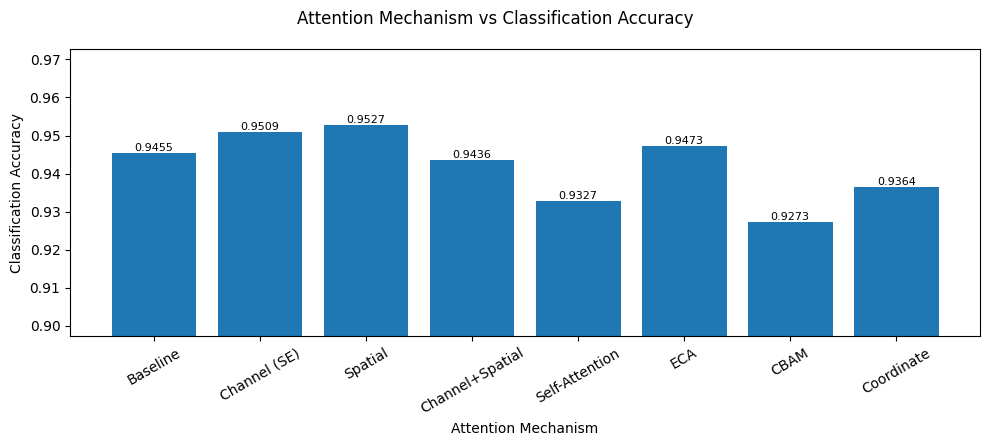

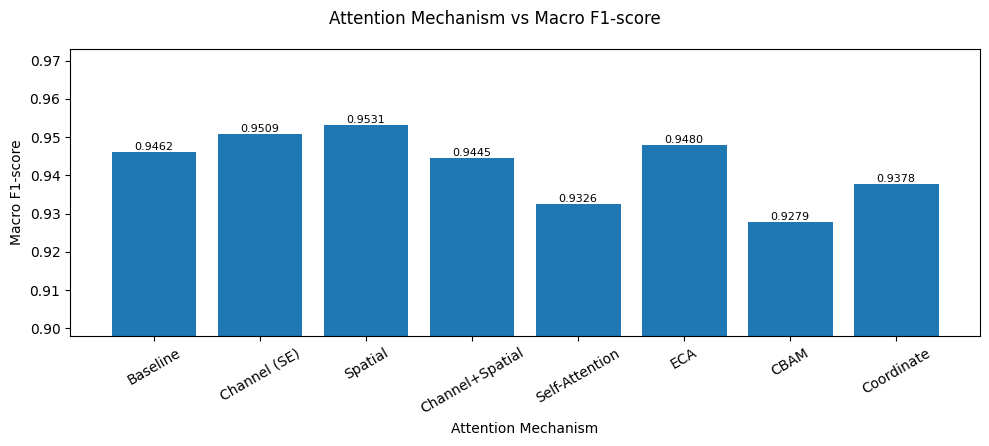

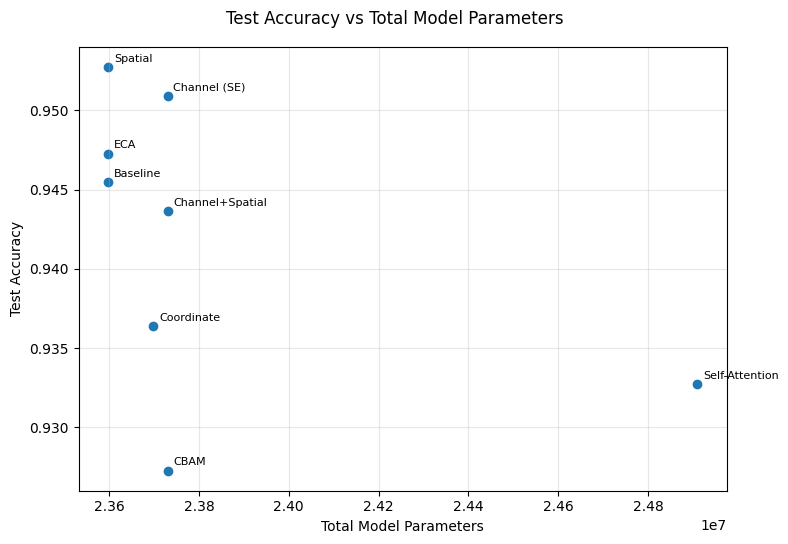

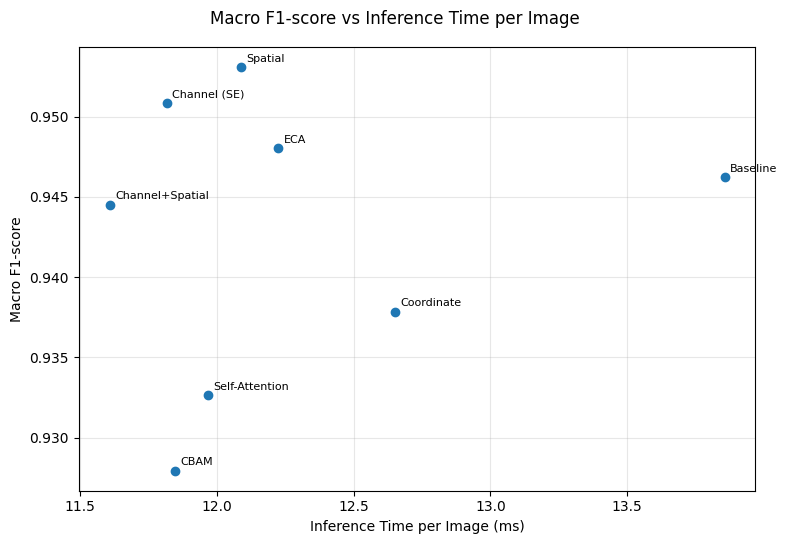


A0_Baseline
              precision    recall  f1-score   support

   dandelion     0.9250    0.9911    0.9569       112
       daisy     1.0000    0.9368    0.9674        95
      tulips     0.9398    0.9328    0.9363       134
  sunflowers     0.9159    0.9608    0.9378       102
       roses     0.9604    0.9065    0.9327       107

    accuracy                         0.9455       550
   macro avg     0.9482    0.9456    0.9462       550
weighted avg     0.9468    0.9455    0.9454       550


A2_Spatial
              precision    recall  f1-score   support

   dandelion     0.9487    0.9911    0.9694       112
       daisy     1.0000    0.9263    0.9617        95
      tulips     0.9343    0.9552    0.9446       134
  sunflowers     0.9412    0.9412    0.9412       102
       roses     0.9528    0.9439    0.9484       107

    accuracy                         0.9527       550
   macro avg     0.9554    0.9515    0.9531       550
weighted avg     0.9535    0.9527    0.9527       55

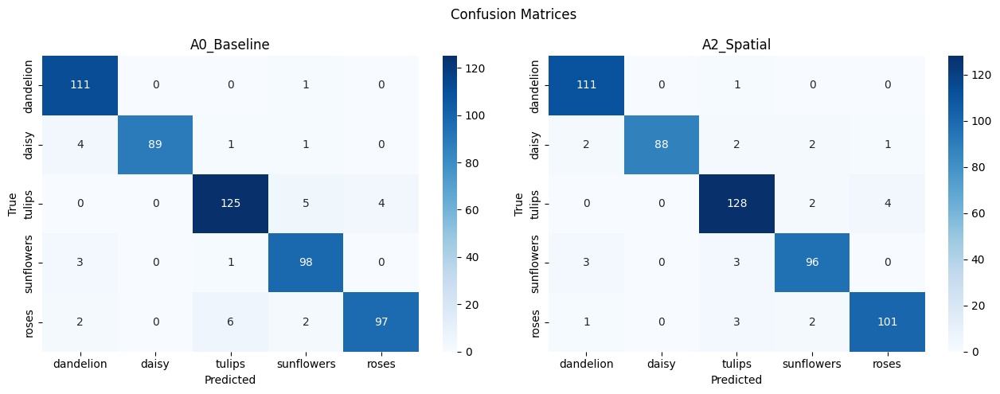

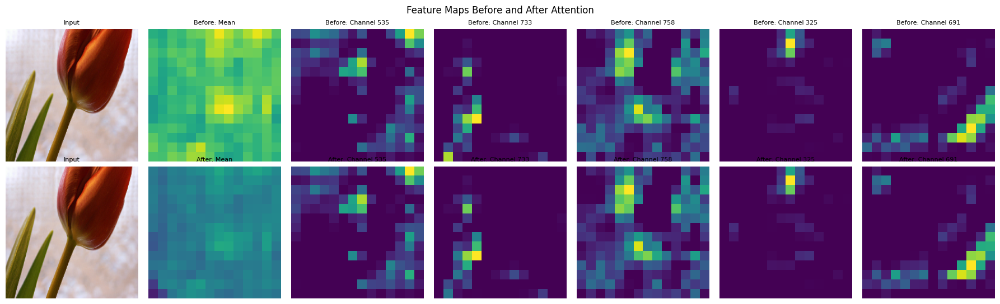

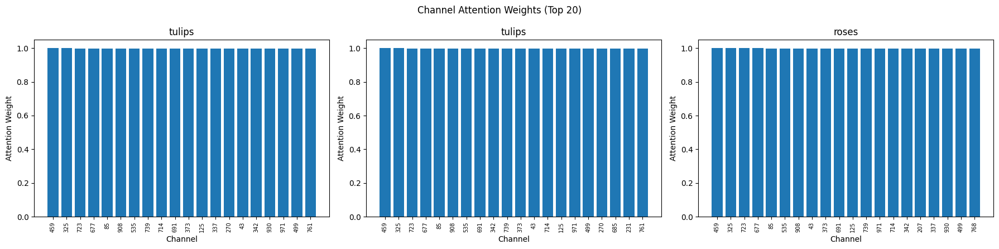

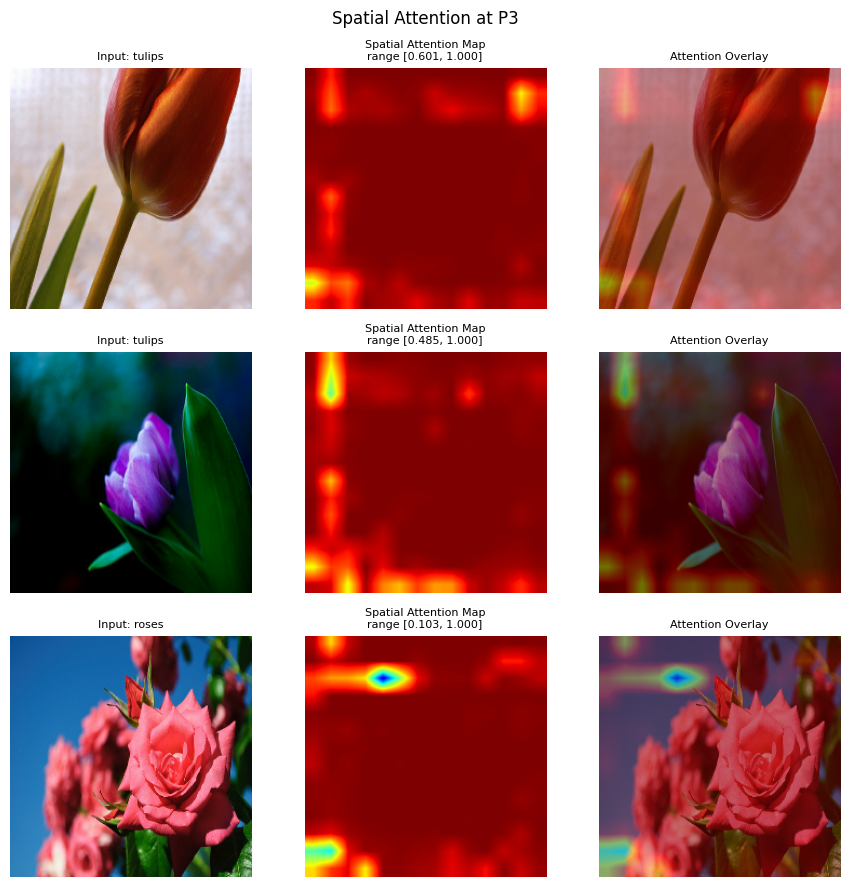

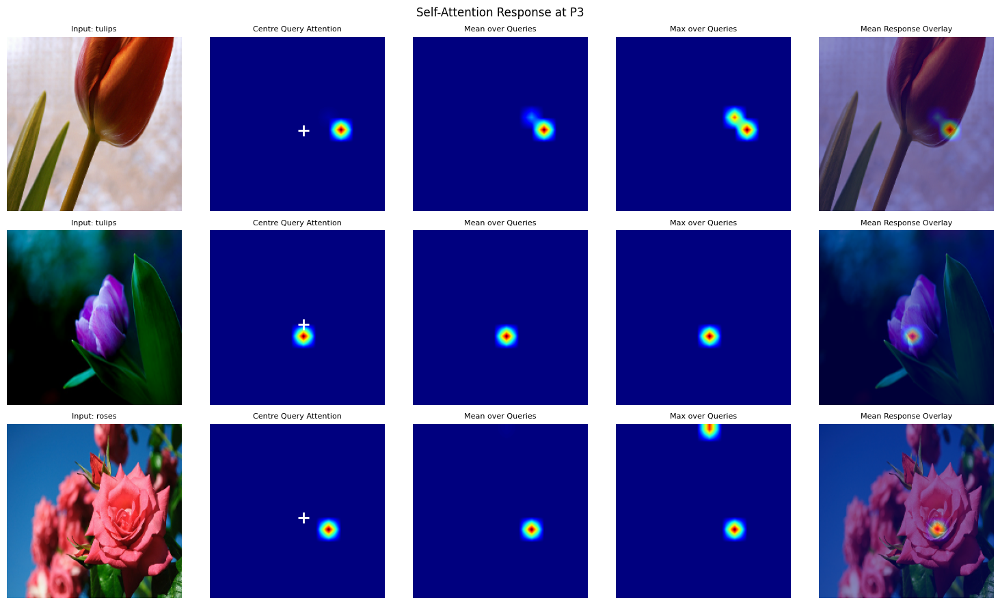

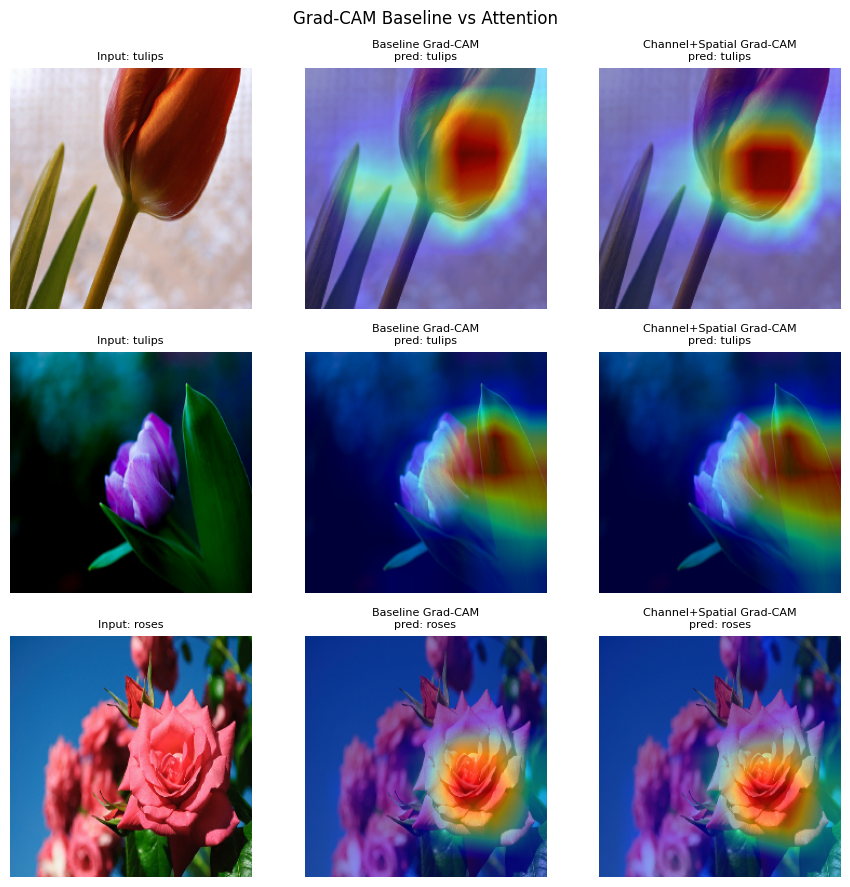

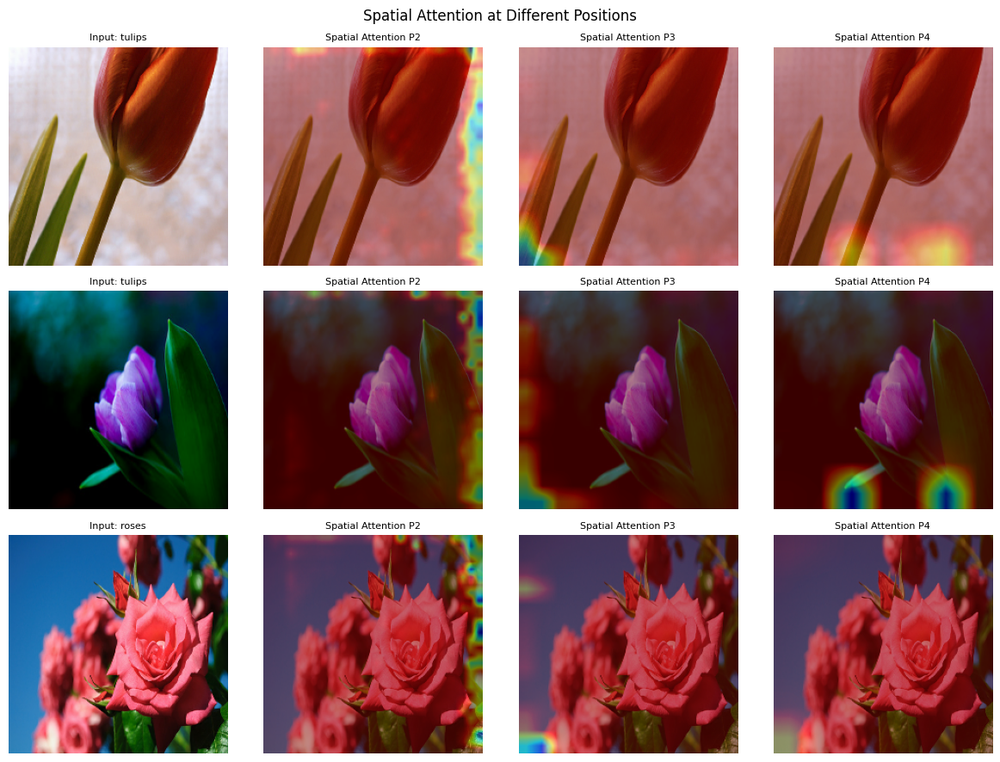

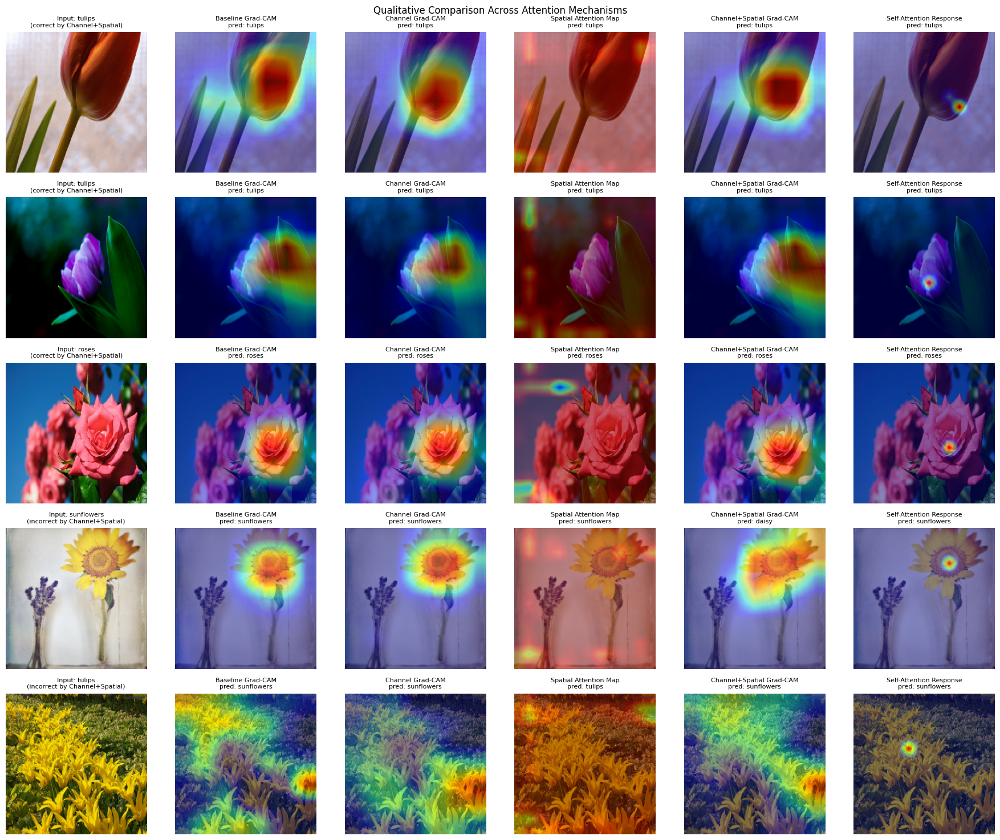

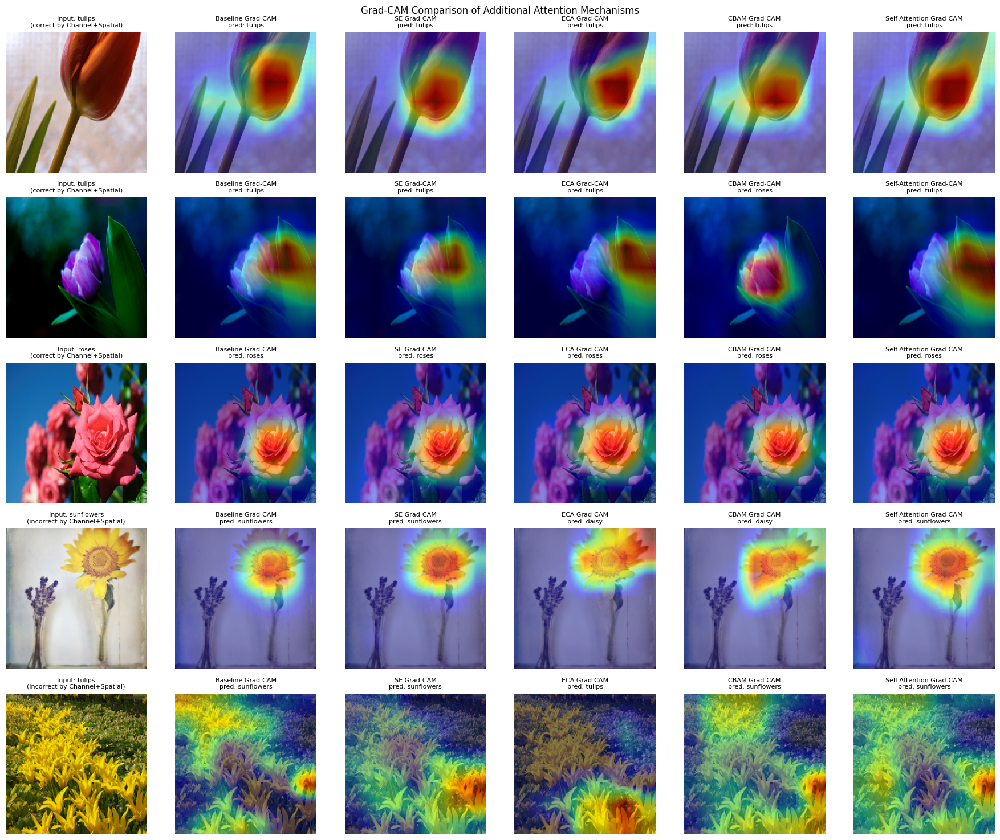

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, time, pickle, math
os.system('pip install -q importlib_resources')
import numpy as np, pandas as pd, tensorflow as tf, tensorflow_datasets as tfds, keras
import matplotlib.pyplot as plt, seaborn as sns
from keras import layers, ops
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

RUN = 'v1'
ROOT = f'/content/drive/MyDrive/CS3807_Exp8_9/{RUN}'
for d in ['models', 'history', 'preds', 'features', 'plots', 'tables', 'tfds']:
    os.makedirs(f'{ROOT}/{d}', exist_ok=True)
SEED, BS, E1, E2, LR1, LR2 = 42, 32, 5, 5, 1e-3, 1e-4
AUTO = tf.data.AUTOTUNE
GPU = bool(tf.config.list_physical_devices('GPU'))
keras.utils.set_random_seed(SEED)

# Dataset (fixed 70:15:15 split)
(tr, va, te), info = tfds.load('tf_flowers', split=['train[:70%]', 'train[70%:85%]', 'train[85%:]'],
                               as_supervised=True, with_info=True, data_dir=f'{ROOT}/tfds')
CLASSES = info.features['label'].names
pre = keras.applications.resnet50.preprocess_input
resize = lambda x, y: (tf.image.resize(x, (224, 224)), tf.one_hot(y, 5))
tr_c = tr.map(resize, num_parallel_calls=AUTO).cache()
val_ds = va.map(resize).batch(BS).map(lambda x, y: (pre(x), y)).cache().prefetch(AUTO)

def train_data():
    aug = keras.Sequential([layers.RandomFlip('horizontal', seed=SEED), layers.RandomRotation(0.05, seed=SEED),
                            layers.RandomZoom(0.1, seed=SEED), layers.RandomTranslation(0.1, 0.1, seed=SEED),
                            layers.RandomContrast(0.1, seed=SEED)])
    return tr_c.shuffle(1000, seed=SEED).batch(BS).map(lambda x, y: (pre(aug(x, training=True)), y),
                                                       num_parallel_calls=AUTO).prefetch(AUTO)

x_test = np.stack([tf.image.resize(x, (224, 224)).numpy() for x, _ in te])
y_test = np.array([int(y) for _, y in te])
XT = pre(x_test.copy())
print('Train/Val/Test:', tr.cardinality().numpy(), va.cardinality().numpy(), len(y_test))


# Attention modules
class ChannelAtt(layers.Layer):
    def __init__(self, c, r=16, use_max=False, **kw):
        super().__init__(**kw)
        self.use_max, self.d1, self.d2 = use_max, layers.Dense(c // r, activation='relu'), layers.Dense(c)
    def attn(self, x):
        a = self.d2(self.d1(ops.mean(x, axis=(1, 2))))
        if self.use_max:
            a = a + self.d2(self.d1(ops.max(x, axis=(1, 2))))
        return ops.sigmoid(a)
    def call(self, x):
        return x * self.attn(x)[:, None, None, :]

class SpatialAtt(layers.Layer):
    def __init__(self, k=7, **kw):
        super().__init__(**kw)
        self.conv = layers.Conv2D(1, k, padding='same', activation='sigmoid')
    def attn(self, x):
        return self.conv(ops.concatenate([ops.mean(x, -1, keepdims=True), ops.max(x, -1, keepdims=True)], -1))
    def call(self, x):
        return x * self.attn(x)

class SelfAtt(layers.Layer):
    def __init__(self, c, **kw):
        super().__init__(**kw)
        self.d = c // 8
        self.q, self.k, self.v = layers.Dense(self.d), layers.Dense(self.d), layers.Dense(c)
        self.gamma = self.add_weight(shape=(), initializer='zeros', name='gamma')
    def attn(self, x):
        h, w, c = x.shape[1:]
        X = ops.reshape(x, (-1, h * w, c))
        return ops.softmax(ops.matmul(self.q(X), ops.transpose(self.k(X), (0, 2, 1))) / math.sqrt(self.d), axis=-1)
    def call(self, x):
        h, w, c = x.shape[1:]
        y = ops.matmul(self.attn(x), self.v(ops.reshape(x, (-1, h * w, c))))
        return x + self.gamma * ops.reshape(y, (-1, h, w, c))

class ECA(layers.Layer):
    def __init__(self, c, **kw):
        super().__init__(**kw)
        t = int(abs((math.log2(c) + 1) / 2))
        self.conv = layers.Conv1D(1, t if t % 2 else t + 1, padding='same', use_bias=False)
    def attn(self, x):
        return ops.sigmoid(self.conv(ops.expand_dims(ops.mean(x, axis=(1, 2)), -1)))[..., 0]
    def call(self, x):
        return x * self.attn(x)[:, None, None, :]

class CoordAtt(layers.Layer):
    def __init__(self, c, r=32, **kw):
        super().__init__(**kw)
        self.conv = layers.Conv2D(max(8, c // r), 1)
        self.bn = layers.BatchNormalization()
        self.ch, self.cw = layers.Conv2D(c, 1, activation='sigmoid'), layers.Conv2D(c, 1, activation='sigmoid')
    def call(self, x, training=False):
        h = x.shape[1]
        y = ops.concatenate([ops.mean(x, 2, keepdims=True), ops.transpose(ops.mean(x, 1, keepdims=True), (0, 2, 1, 3))], 1)
        y = self.bn(self.conv(y), training=training)
        y = y * ops.relu6(y + 3) / 6
        return x * self.ch(y[:, :h]) * ops.transpose(self.cw(y[:, h:]), (0, 2, 1, 3))

MODS = {'ca': lambda c, k, n: ChannelAtt(c, name=n),
        'cbam_ca': lambda c, k, n: ChannelAtt(c, use_max=True, name=n),
        'sa': lambda c, k, n: SpatialAtt(k, name=n),
        'self': lambda c, k, n: SelfAtt(c, name=n),
        'eca': lambda c, k, n: ECA(c, name=n),
        'coord': lambda c, k, n: CoordAtt(c, name=n)}
POS = {'conv2': 'P1', 'conv3': 'P2', 'conv4': 'P3', 'conv5': 'P4'}


# ResNet50 rebuilt with insertion points, loaded with ImageNet weights
BASE = keras.applications.ResNet50(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
BB = {l.name for l in BASE.layers}

def cb(x, f, k, s, n, act=True):
    x = layers.Conv2D(f, k, strides=s, padding='same' if k == 3 else 'valid', name=n + '_conv')(x)
    x = layers.BatchNormalization(epsilon=1.001e-5, name=n + '_bn')(x)
    return layers.Activation('relu', name=n + '_relu')(x) if act else x

def block(x, f, s, short, n):
    sc = cb(x, 4 * f, 1, s, n + '_0', False) if short else x
    y = cb(cb(cb(x, f, 1, s, n + '_1'), f, 3, 1, n + '_2'), 4 * f, 1, 1, n + '_3', False)
    return layers.Activation('relu', name=n + '_out')(layers.Add(name=n + '_add')([sc, y]))

def build(spec):
    inp = keras.Input((224, 224, 3))
    x = cb(layers.ZeroPadding2D(3, name='conv1_pad')(inp), 64, 7, 2, 'conv1')
    x = layers.MaxPooling2D(3, strides=2, name='pool1_pool')(layers.ZeroPadding2D(1, name='pool1_pad')(x))
    for st, f, nb, s in [('conv2', 64, 3, 1), ('conv3', 128, 4, 2), ('conv4', 256, 6, 2), ('conv5', 512, 3, 2)]:
        for b in range(1, nb + 1):
            x = block(x, f, s if b == 1 else 1, b == 1, f'{st}_block{b}')
        for code in spec.get(POS[st], []):
            x = MODS[code](x.shape[-1], spec.get('k', 7), f'{POS[st]}_{code}')(x)
    x = layers.Dropout(0.3, name='drop')(layers.GlobalAveragePooling2D(name='gap')(x))
    m = keras.Model(inp, layers.Activation('softmax', name='pred')(layers.Dense(5, name='logits')(x)))
    for l in BASE.layers:
        if l.weights:
            m.get_layer(l.name).set_weights(l.get_weights())
    return m

def set_trainable(m, ft):
    for l in m.layers:
        l.trainable = l.name not in BB or (ft and l.name.startswith('conv5') and not isinstance(l, layers.BatchNormalization))


# Training with timestamped, auto-reloading checkpoints
def latest(pat):
    f = sorted(glob.glob(pat))
    return f[-1] if f else None

def run(name, spec):
    keras.utils.set_random_seed(SEED)
    m, hist = build(spec), {}
    for ph, lr, ep in [(1, LR1, E1), (2, LR2, E2)]:
        set_trainable(m, ph == 2)
        m.compile(optimizer=keras.optimizers.Adam(lr), loss='categorical_crossentropy', metrics=['accuracy'])
        w = latest(f'{ROOT}/models/{name}_ph{ph}_*.weights.h5')
        if w:
            m.load_weights(w)
            h = pickle.load(open(f"{ROOT}/history/{os.path.basename(w).replace('.weights.h5', '.pkl')}", 'rb'))
        else:
            if GPU: tf.config.experimental.reset_memory_stats('GPU:0')
            t0 = time.time()
            h = m.fit(train_data(), validation_data=val_ds, epochs=ep, verbose=2).history
            h['time'] = time.time() - t0
            h['mem'] = tf.config.experimental.get_memory_info('GPU:0')['peak'] / 2**20 if GPU else np.nan
            stamp = f"{name}_ph{ph}_{time.strftime('%Y%m%d-%H%M%S')}"
            m.save_weights(f'{ROOT}/models/{stamp}.weights.h5')
            pickle.dump(h, open(f'{ROOT}/history/{stamp}.pkl', 'wb'))
        hist[ph] = h
    return m, hist

pred = lambda n: np.load(f'{ROOT}/preds/{n}.npy').argmax(1)
is_att = lambda l: l.name[:3] in ('P1_', 'P2_', 'P3_', 'P4_')

def evaluate(name, m, h, spec):
    pf = f'{ROOT}/preds/{name}.npy'
    if not os.path.exists(pf):
        np.save(pf, m.predict(XT, batch_size=BS, verbose=0))
    prob = np.load(pf)
    yp = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_test, yp, average='macro', zero_division=0)
    fn, xs = tf.function(lambda x: m(x, training=False)), tf.constant(XT[:110])
    for i in range(10):
        fn(xs[i:i + 1])
    t0 = time.perf_counter()
    for i in range(10, 110):
        fn(xs[i:i + 1]).numpy()
    inf = (time.perf_counter() - t0) * 10
    return dict(Position='+'.join(p_ for p_ in ['P1', 'P2', 'P3', 'P4'] if p_ in spec) or '-',
                Accuracy=accuracy_score(y_test, yp), Precision=p, Recall=r, F1=f,
                TestLoss=-np.mean(np.log(prob[np.arange(len(y_test)), y_test] + 1e-12)),
                TrainAcc=h[2]['accuracy'][-1], ValAcc=h[2]['val_accuracy'][-1],
                TrainLoss=h[2]['loss'][-1], ValLoss=h[2]['val_loss'][-1],
                TrainableParams=sum(int(np.prod(v.shape)) for v in m.trainable_weights), TotalParams=m.count_params(),
                AttnParams=sum(l.count_params() for l in m.layers if is_att(l)), InferenceMs=inf,
                TrainTimeS=h[1]['time'] + h[2]['time'], PeakMemMB=max(h[1]['mem'], h[2]['mem']))


# Experiments
CS = ['ca', 'sa']
EXPS = {'A0_Baseline': {}, 'A1_Channel': {'P3': ['ca']}, 'A2_Spatial': {'P3': ['sa']},
        'A3_ChannelSpatial': {'P3': CS}, 'A4_SelfAttention': {'P3': ['self']}, 'A5_Combined': {'P3': CS + ['self']},
        'B1_P1': {'P1': CS}, 'B2_P2': {'P2': CS}, 'B4_P4': {'P4': CS},
        'C_P3P4': {'P3': CS, 'P4': CS}, 'C_P2P3P4': {'P2': CS, 'P3': CS, 'P4': CS},
        'D_SpatialChannel': {'P3': ['sa', 'ca']},
        'E_k3': {'P3': CS, 'k': 3}, 'E_k5': {'P3': CS, 'k': 5},
        'F_ECA': {'P3': ['eca']}, 'F_CBAM': {'P3': ['cbam_ca', 'sa']}, 'F_CoordAtt': {'P3': ['coord']}}
KEEP = ['A0_Baseline', 'A1_Channel', 'A2_Spatial', 'A3_ChannelSpatial', 'A4_SelfAttention', 'B2_P2', 'B4_P4', 'F_ECA', 'F_CBAM']

RES = f'{ROOT}/tables/results.csv'
res = pd.read_csv(RES, index_col=0).to_dict('index') if os.path.exists(RES) else {}
models, hists, dims = {}, {}, []
for name, spec in EXPS.items():
    m, hists[name] = run(name, spec)
    if name not in res:
        res[name] = evaluate(name, m, hists[name], spec)
        pd.DataFrame.from_dict(res, orient='index').to_csv(RES)
    dims += [dict(Model=name, Module=l.name, Input=str(tuple(l.input.shape[1:])), Output=str(tuple(l.output.shape[1:])),
                  Params=l.count_params()) for l in m.layers if is_att(l)]
    if name in KEEP:
        models[name] = m
R = pd.DataFrame.from_dict(res, orient='index')


# Tables
def table(title, rows, cols, labels=None):
    t = R.loc[rows, cols].copy()
    if labels: t.index = labels
    print(f'\n{title}\n' + t.to_string(float_format=lambda v: f'{v:.4f}'))
    t.to_csv(f'{ROOT}/tables/{title}.csv')

b = models['A0_Baseline']
st = pd.DataFrame([(n, str(tuple(b.get_layer(l).output.shape[1:]))) for n, l in
                   [('Stem + MaxPool', 'pool1_pool'), ('conv2_x', 'conv2_block3_out'), ('conv3_x', 'conv3_block4_out'),
                    ('conv4_x', 'conv4_block6_out'), ('conv5_x', 'conv5_block3_out')]], columns=['Stage', 'Output (H, W, C)'])
print('\nResNet50 Stage Dimensions\n' + st.to_string(index=False))
st.to_csv(f'{ROOT}/tables/ResNet50 Stage Dimensions.csv', index=False)
dims = pd.DataFrame(dims)
print('\nAttention Module Input and Output Dimensions\n' + dims.to_string(index=False))
dims.to_csv(f'{ROOT}/tables/Attention Module Dimensions.csv', index=False)

MET = ['Accuracy', 'Precision', 'Recall', 'F1', 'TrainableParams', 'TotalParams', 'AttnParams', 'InferenceMs']
table('Attention Type Ablation at P3', list(EXPS)[:6], MET + ['TrainAcc', 'ValAcc', 'TrainLoss', 'ValLoss', 'TestLoss'])
table('Attention Position Ablation (Channel-Spatial)', ['B1_P1', 'B2_P2', 'A3_ChannelSpatial', 'B4_P4'], MET,
      ['B1 P1 (56x56x256)', 'B2 P2 (28x28x512)', 'B3 P3 (14x14x1024)', 'B4 P4 (7x7x2048)'])
table('Multiple Attention Positions', ['A3_ChannelSpatial', 'B4_P4', 'C_P3P4', 'C_P2P3P4'],
      ['Accuracy', 'F1', 'TotalParams', 'AttnParams', 'PeakMemMB', 'TrainTimeS', 'InferenceMs'], ['P3', 'P4', 'P3+P4', 'P2+P3+P4'])
table('Attention Order at P3', ['A3_ChannelSpatial', 'D_SpatialChannel'], MET, ['Channel then Spatial', 'Spatial then Channel'])
table('Spatial Attention Kernel Size', ['E_k3', 'E_k5', 'A3_ChannelSpatial'], ['Accuracy', 'F1', 'InferenceMs'], ['3x3', '5x5', '7x7'])
MECH = {'Baseline': 'A0_Baseline', 'Channel (SE)': 'A1_Channel', 'Spatial': 'A2_Spatial',
        'Channel+Spatial': 'A3_ChannelSpatial', 'Self-Attention': 'A4_SelfAttention',
        'ECA': 'F_ECA', 'CBAM': 'F_CBAM', 'Coordinate': 'F_CoordAtt'}
table('Attention Mechanism Comparison at P3', list(MECH.values()), MET, list(MECH))
table('Main Results', ['A0_Baseline', 'A1_Channel', 'A2_Spatial', 'B2_P2', 'A3_ChannelSpatial', 'B4_P4',
                       'A4_SelfAttention', 'F_ECA', 'F_CBAM'], ['Position'] + MET,
      ['Baseline', 'Channel', 'Spatial', 'Channel+Spatial', 'Channel+Spatial', 'Channel+Spatial',
       'Self-Attention', 'ECA', 'CBAM'])


# Plot helpers
def save(title, **arr):
    plt.suptitle(title)
    plt.tight_layout()
    fn = title.replace(' ', '_')
    plt.savefig(f'{ROOT}/plots/{fn}.png', dpi=200, bbox_inches='tight')
    plt.show()
    if arr: np.savez(f'{ROOT}/features/{fn}.npz', **arr)

def show(ax, img=None, mp=None, title=''):
    if img is not None: ax.imshow(np.clip(img, 0, 255).astype('uint8'))
    if mp is not None: ax.imshow(mp, cmap='jet', alpha=0.45 if img is not None else 1, vmin=0, vmax=1)
    ax.set_title(title, fontsize=8)
    ax.axis('off')

norm = lambda a: (a - a.min()) / (a.max() - a.min() + 1e-8)
up = lambda a: tf.image.resize(np.asarray(a, 'float32')[..., None], (224, 224)).numpy()[..., 0]
feat = lambda m, ln, idx: keras.Model(m.input, m.get_layer(ln).input)(XT[idx], training=False)

def gradcam(n, idx):
    m, c = models[n], pred(n)[idx]
    g = keras.Model(m.input, [m.get_layer('gap').input, m.get_layer('logits').output])
    with tf.GradientTape() as t:
        a, z = g(tf.constant(XT[idx]), training=False)
        s = tf.reduce_sum(z * tf.one_hot(c, 5), 1)
    gr = t.gradient(s, a)
    cam = tf.nn.relu(tf.reduce_sum(a * tf.reduce_mean(gr, (1, 2), keepdims=True), -1)).numpy()
    return np.stack([norm(up(a_)) for a_ in cam]), c

def smap(m, ln, idx):
    return np.stack([up(s[..., 0]) for s in np.asarray(m.get_layer(ln).attn(feat(m, ln, idx)))])

def selfmaps(m, idx):
    f = feat(m, 'P3_self', idx)
    a, (h, w) = np.asarray(m.get_layer('P3_self').attn(f)), f.shape[1:3]
    q = (h // 2) * w + w // 2
    return [np.stack([norm(up(v.reshape(h, w))) for v in arr]) for arr in (a[:, q], a.mean(1), a.max(1))]

pa3 = pred('A3_ChannelSpatial')
rng = np.random.default_rng(SEED)
ok, bad = np.where(pa3 == y_test)[0], np.where(pa3 != y_test)[0]
IDX = list(rng.choice(ok, 3, replace=False)) + list(rng.choice(bad, min(2, len(bad)), replace=False))
S3 = IDX[:3]


# Sample images
fig, ax = plt.subplots(1, 5, figsize=(15, 3.5))
for a, c in zip(ax, range(5)):
    show(a, x_test[np.where(y_test == c)[0][0]], title=CLASSES[c])
save('Sample Images from All Classes')

# Training curves
ep = range(1, E1 + E2 + 1)
for key, lab in [('accuracy', 'Accuracy'), ('loss', 'Loss')]:
    fig, ax = plt.subplots(2, 3, figsize=(16, 8))
    for a, n in zip(ax.flat, list(EXPS)[:6]):
        h = hists[n]
        a.plot(ep, h[1][key] + h[2][key], label='Train')
        a.plot(ep, h[1]['val_' + key] + h[2]['val_' + key], label='Validation')
        a.axvline(E1 + 0.5, ls='--', c='gray', label='Fine-tuning starts')
        a.set_title(n)
        a.set_xlabel('Epoch')
        a.set_ylabel(lab)
        a.legend()
    save(f'Training and Validation {lab}')

# Performance comparisons
M = R.loc[list(MECH.values())]
for col, lab in [('Accuracy', 'Classification Accuracy'), ('F1', 'Macro F1-score')]:
    plt.figure(figsize=(10, 4.5))
    bars = plt.bar(list(MECH), M[col])
    plt.bar_label(bars, fmt='%.4f', fontsize=8)
    plt.ylim(M[col].min() - 0.03, min(1, M[col].max() + 0.02))
    plt.xlabel('Attention Mechanism')
    plt.ylabel(lab)
    plt.xticks(rotation=30)
    save(f'Attention Mechanism vs {lab}')
for x, y, xl, yl in [('TotalParams', 'Accuracy', 'Total Model Parameters', 'Test Accuracy'),
                     ('InferenceMs', 'F1', 'Inference Time per Image (ms)', 'Macro F1-score')]:
    plt.figure(figsize=(8, 5.5))
    plt.scatter(M[x], M[y])
    for k, v in MECH.items():
        plt.annotate(k, (M.loc[v, x], M.loc[v, y]), fontsize=8, xytext=(4, 4), textcoords='offset points')
    plt.xlabel(xl)
    plt.ylabel(yl)
    plt.grid(alpha=0.3)
    save(f'{yl} vs {xl.split(" (")[0]}')

# Confusion matrices
best = M.drop('A0_Baseline')['F1'].astype(float).idxmax()
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
cms = {}
for a, n in zip(ax, ['A0_Baseline', best]):
    yp = pred(n)
    cms[n] = confusion_matrix(y_test, yp)
    sns.heatmap(cms[n], annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=a)
    a.set_title(n)
    a.set_xlabel('Predicted')
    a.set_ylabel('True')
    print(f'\n{n}\n' + classification_report(y_test, yp, target_names=CLASSES, digits=4))
save('Confusion Matrices', **cms)

# Feature maps before and after attention (Channel+Spatial at P3)
m = models['A3_ChannelSpatial']
i = IDX[:1]
fb = np.asarray(feat(m, 'P3_ca', i))[0]
fa = np.asarray(keras.Model(m.input, m.get_layer('P3_sa').output)(XT[i], training=False))[0]
top = np.argsort(np.asarray(m.get_layer('P3_ca').attn(fb[None]))[0])[::-1][:5]
fig, ax = plt.subplots(2, 7, figsize=(18, 5.5))
for r in range(2):
    show(ax[r, 0], x_test[i[0]], title='Input')
for j, c in enumerate(['mean'] + list(top)):
    pair = (fb.mean(-1), fa.mean(-1)) if c == 'mean' else (fb[..., c], fa[..., c])
    vmax = max(pair[0].max(), pair[1].max())
    for r, (mp, lab) in enumerate(zip(pair, ['Before', 'After'])):
        ax[r, j + 1].imshow(mp, cmap='viridis', vmin=0, vmax=vmax)
        ax[r, j + 1].set_title(f"{lab}: {'Mean' if c == 'mean' else f'Channel {c}'}", fontsize=8)
        ax[r, j + 1].axis('off')
save('Feature Maps Before and After Attention', before=fb, after=fa, channels=top)

# Channel-attention weights (top 20)
m = models['A1_Channel']
w = np.asarray(m.get_layer('P3_ca').attn(feat(m, 'P3_ca', S3)))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, i, wi in zip(ax, S3, w):
    t = np.argsort(wi)[::-1][:20]
    a.bar(range(20), wi[t])
    a.set_xticks(range(20), t, rotation=90, fontsize=7)
    a.set_title(CLASSES[y_test[i]])
    a.set_xlabel('Channel')
    a.set_ylabel('Attention Weight')
save('Channel Attention Weights (Top 20)', weights=w, idx=S3)

# Spatial attention map and overlay
sp = smap(models['A2_Spatial'], 'P3_sa', S3)
fig, ax = plt.subplots(3, 3, figsize=(9, 9))
for r, i in enumerate(S3):
    show(ax[r, 0], x_test[i], title=f'Input: {CLASSES[y_test[i]]}')
    show(ax[r, 1], mp=sp[r], title=f'Spatial Attention Map\nrange [{sp[r].min():.3f}, {sp[r].max():.3f}]')
    show(ax[r, 2], x_test[i], sp[r], 'Attention Overlay')
save('Spatial Attention at P3', maps=sp, idx=S3)

# Self-attention response
sq, smean, smax = selfmaps(models['A4_SelfAttention'], S3)
fig, ax = plt.subplots(3, 5, figsize=(15, 9))
for r, i in enumerate(S3):
    show(ax[r, 0], x_test[i], title=f'Input: {CLASSES[y_test[i]]}')
    show(ax[r, 1], mp=sq[r], title='Centre Query Attention')
    ax[r, 1].plot(120, 120, 'w+', ms=12, mew=2)
    show(ax[r, 2], mp=smean[r], title='Mean over Queries')
    show(ax[r, 3], mp=smax[r], title='Max over Queries')
    show(ax[r, 4], x_test[i], smean[r], 'Mean Response Overlay')
save('Self-Attention Response at P3', centre=sq, mean=smean, max=smax, idx=S3)

# Grad-CAM: baseline vs attention model
gb, pb = gradcam('A0_Baseline', S3)
ga, pa = gradcam('A3_ChannelSpatial', S3)
fig, ax = plt.subplots(3, 3, figsize=(9, 9))
for r, i in enumerate(S3):
    show(ax[r, 0], x_test[i], title=f'Input: {CLASSES[y_test[i]]}')
    show(ax[r, 1], x_test[i], gb[r], f'Baseline Grad-CAM\npred: {CLASSES[pb[r]]}')
    show(ax[r, 2], x_test[i], ga[r], f'Channel+Spatial Grad-CAM\npred: {CLASSES[pa[r]]}')
save('Grad-CAM Baseline vs Attention', baseline=gb, attention=ga, idx=S3)

# Spatial attention at P2, P3, P4
pm = {p: smap(models[n], f'{p}_sa', S3) for p, n in [('P2', 'B2_P2'), ('P3', 'A3_ChannelSpatial'), ('P4', 'B4_P4')]}
fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for r, i in enumerate(S3):
    show(ax[r, 0], x_test[i], title=f'Input: {CLASSES[y_test[i]]}')
    for j, p in enumerate(pm):
        show(ax[r, j + 1], x_test[i], pm[p][r], f'Spatial Attention {p}')
save('Spatial Attention at Different Positions', **pm)

# Qualitative comparison: 3 correct, 2 incorrect
gc = {n: gradcam(n, IDX) for n in ['A0_Baseline', 'A1_Channel', 'A3_ChannelSpatial', 'A4_SelfAttention', 'F_ECA', 'F_CBAM']}
sp5, (_, sm5, _) = smap(models['A2_Spatial'], 'P3_sa', IDX), selfmaps(models['A4_SelfAttention'], IDX)
p2, p4 = pred('A2_Spatial')[IDX], pred('A4_SelfAttention')[IDX]
fig, ax = plt.subplots(len(IDX), 6, figsize=(18, 3 * len(IDX)))
for r, i in enumerate(IDX):
    show(ax[r, 0], x_test[i], title=f"Input: {CLASSES[y_test[i]]}\n({'correct' if r < 3 else 'incorrect'} by Channel+Spatial)")
    for j, (n, lab) in enumerate([('A0_Baseline', 'Baseline'), ('A1_Channel', 'Channel')]):
        show(ax[r, j + 1], x_test[i], gc[n][0][r], f'{lab} Grad-CAM\npred: {CLASSES[gc[n][1][r]]}')
    show(ax[r, 3], x_test[i], sp5[r], f'Spatial Attention Map\npred: {CLASSES[p2[r]]}')
    show(ax[r, 4], x_test[i], gc['A3_ChannelSpatial'][0][r], f"Channel+Spatial Grad-CAM\npred: {CLASSES[gc['A3_ChannelSpatial'][1][r]]}")
    show(ax[r, 5], x_test[i], sm5[r], f'Self-Attention Response\npred: {CLASSES[p4[r]]}')
save('Qualitative Comparison Across Attention Mechanisms', spatial=sp5, self_mean=sm5, idx=IDX,
     **{n: v[0] for n, v in gc.items()})

# Additional mechanisms: Grad-CAM comparison
fig, ax = plt.subplots(len(IDX), 6, figsize=(18, 3 * len(IDX)))
for r, i in enumerate(IDX):
    show(ax[r, 0], x_test[i], title=f"Input: {CLASSES[y_test[i]]}\n({'correct' if r < 3 else 'incorrect'} by Channel+Spatial)")
    for j, (n, lab) in enumerate([('A0_Baseline', 'Baseline'), ('A1_Channel', 'SE'), ('F_ECA', 'ECA'),
                                  ('F_CBAM', 'CBAM'), ('A4_SelfAttention', 'Self-Attention')]):
        show(ax[r, j + 1], x_test[i], gc[n][0][r], f'{lab} Grad-CAM\npred: {CLASSES[gc[n][1][r]]}')
save('Grad-CAM Comparison of Additional Attention Mechanisms')